<a href="https://colab.research.google.com/github/Nasr-allah124/Tp2_Apprentissage_Profond_avec-_TensorFlow_Keras/blob/main/TP2__Apprentissage_Profond_avec_TensorFlow_Keras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercice 1

In [4]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Réponses aux questions : Étape 1 (Import des bibliothèques)

**1. Quelle est la différence entre TensorFlow et Keras ?**
TensorFlow est le moteur de calcul (tenseurs, CPU/GPU, calcul automatique des gradients). Keras est l'API haut niveau intégrée dans TensorFlow (`tf.keras`) qui permet de construire des modèles simplement.

**2. À quoi sert la couche `Flatten` ?**
Elle transforme chaque image 2D (28×28) en un vecteur 1D de 784 valeurs, car une couche `Dense` attend une entrée 1D.

**3. Quelle version de TensorFlow est installée ?**
TensorFlow **2.21.0**.

**4. À quoi servent `Sequential` et `Dense` ?**
- `Sequential` : empile les couches les unes après les autres (modèle linéaire).
- `Dense` : couche entièrement connectée, chaque neurone est relié à tous les neurones de la couche précédente.

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Avant normalisation :", x_train.dtype, x_train.min(), x_train.max())

# Normalisation
x_train = x_train / 255.0
x_test = x_test / 255.0

print("Après normalisation :", x_train.dtype, x_train.min(), x_train.max())
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Avant normalisation : uint8 0 255
Après normalisation : float64 0.0 1.0
x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape: (10000, 28, 28)


## Réponses aux questions : Étape 2 (Chargement et préparation du dataset)

**1. Pourquoi normalise-t-on les valeurs des pixels ?**
Les pixels vont de 0 à 255. Les ramener entre 0 et 1 rend l'entraînement plus stable et accélère la convergence.

**2. Quelle est la taille d'une image et son type de données ?**
Taille : 28×28 pixels (niveaux de gris). Type : `uint8` (0 à 255) avant normalisation, `float64` après la division par 255.0.

**3. Combien d'exemples contient le jeu d'entraînement ?**
60 000 exemples (`x_train.shape = (60000, 28, 28)`), plus 10 000 pour le test.

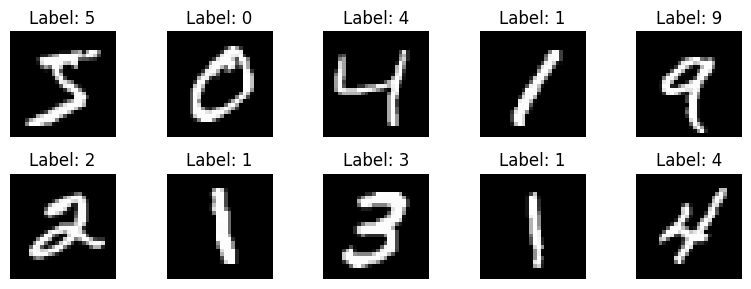

In [3]:
plt.figure(figsize=(8, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

## Réponses aux questions : Étape 3 (Visualisation d'échantillons)

**À faire :** les chiffres affichés sont : 5, 0, 4, 1, 9, 2, 1, 3, 1, 4. Les labels correspondent bien aux images.

**1. Quelle commande permet de modifier le nombre d'images affichées ?**
On modifie `range(10)` et la grille `plt.subplot(lignes, colonnes, i+1)`. Exemple pour 20 images : `range(20)` et `plt.subplot(4, 5, i+1)`.

**2. Que représente `cmap='gray'` ?**
C'est la palette de couleurs : l'image s'affiche en niveaux de gris (0 = noir, 1 = blanc).

**3. Quelle utilité a cette étape dans un projet d'IA ?**
Vérifier que les données sont correctes (chargement, cohérence images/labels) avant l'entraînement, pour éviter des erreurs coûteuses plus tard.

In [5]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Réponses aux questions : Étape 4 (Construction du modèle)

**1. Combien de paramètres le modèle contient-il ?**
- Dense(128) : 784 × 128 + 128 = 100 480
- Dense(10) : 128 × 10 + 10 = 1 290
- **Total : 101 770 paramètres**

**2. Quelle est la fonction d'activation de la couche de sortie ? Pourquoi ?**
`softmax`. Elle transforme les 10 sorties en probabilités dont la somme vaut 1, ce qui convient à la classification multiclasse (chiffres 0 à 9).

**3. Quelle est la différence entre ReLU et Softmax ?**
- **ReLU** : `max(0, x)`. Utilisée dans les couches cachées pour introduire de la non-linéarité.
- **Softmax** : donne une distribution de probabilités. Utilisée en sortie pour la classification multiclasse.

In [6]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## Réponses aux questions : Étape 5 (Compilation du modèle)

**1. Qu'est-ce qu'un optimiseur ?**
C'est l'algorithme qui met à jour les poids du réseau à partir du gradient de la perte, afin de la réduire (exemples : Adam, SGD, RMSprop).

**2. Pourquoi utilise-t-on une fonction de perte ?**
Elle mesure l'écart entre la prédiction du modèle et la vraie valeur. C'est la quantité que l'entraînement cherche à minimiser.

**3. Que se passe-t-il si on change la fonction de perte ?**
Le modèle optimise un autre critère. Une perte inadaptée à la tâche donne de mauvais résultats ou une erreur. Exemple : `categorical_crossentropy` exige des labels en one-hot, alors que `sparse_categorical_crossentropy` accepte des entiers.

**4. Quelle serait la conséquence d'un mauvais choix d'optimiseur ?**
Convergence lente, blocage dans un mauvais minimum, ou instabilité (la perte oscille ou diverge), surtout avec un mauvais taux d'apprentissage.

**5. Quelle est la différence entre `loss` et `metrics` ?**
- `loss` : valeur que le modèle minimise pendant l'entraînement (elle doit être dérivable).
- `metrics` : mesure pour nous, pour évaluer la performance (ex. accuracy). Elle n'influence pas l'apprentissage.

In [7]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_data=(x_test, y_test)
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9233 - loss: 0.2674 - val_accuracy: 0.9546 - val_loss: 0.1547
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9647 - loss: 0.1192 - val_accuracy: 0.9670 - val_loss: 0.1109
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9752 - loss: 0.0819 - val_accuracy: 0.9711 - val_loss: 0.0924
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9818 - loss: 0.0594 - val_accuracy: 0.9758 - val_loss: 0.0822
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9854 - loss: 0.0468 - val_accuracy: 0.9784 - val_loss: 0.0783


## Réponses aux questions : Étape 6 (Entraînement du modèle)

**À observer :**
- La précision d'entraînement augmente d'époque en époque.
- La précision de validation suit la même tendance, avec une valeur proche ou légèrement inférieure.

**1. Que représente une « époque » ?**
Un passage complet du modèle sur tout le jeu d'entraînement (ici 60 000 images).

**2. Pourquoi utilise-t-on un jeu de validation ?**
Pour mesurer la performance sur des données non utilisées pour ajuster les poids, et détecter le surapprentissage pendant l'entraînement.

**3. Que se passerait-il avec 50 époques ?**
La précision d'entraînement approcherait 100 % tandis que la validation stagnerait ou baisserait : c'est du surapprentissage (le modèle mémorise les données). Le temps d'entraînement serait aussi 10 fois plus long.

In [8]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9784 - loss: 0.0783
Test accuracy: 0.9784
Test loss: 0.0783


## Réponses aux questions : Étape 7 (Évaluation du modèle)

**1. Quelle est la précision finale de votre modèle ?**
Test accuracy ≈ 0.9784

**2. Pourquoi la précision du test est souvent inférieure à celle d'entraînement ?**
Le modèle est ajusté sur les données d'entraînement, il les connaît donc mieux. Sur des données jamais vues, il généralise un peu moins bien.

**3. Que faire si le modèle surapprend ?**
- Réduire le nombre d'époques (early stopping)
- Ajouter du Dropout ou de la régularisation
- Simplifier le modèle
- Augmenter la quantité de données (data augmentation)

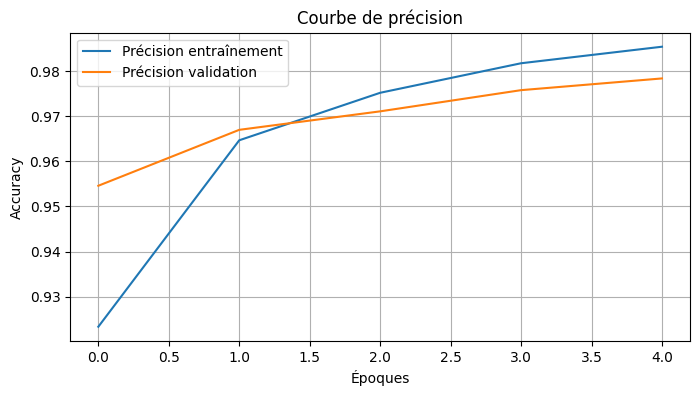

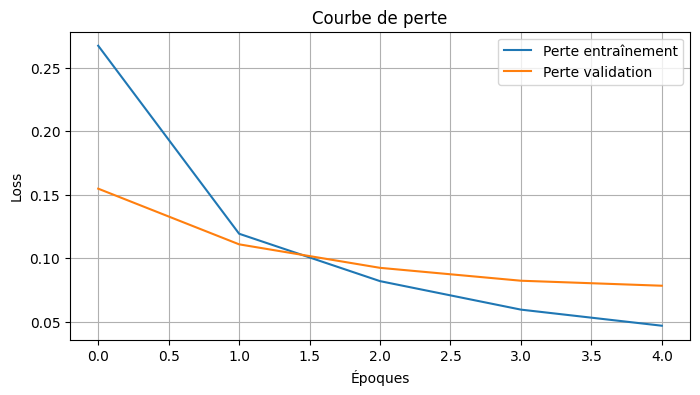

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='Précision entraînement')
plt.plot(history.history['val_accuracy'], label='Précision validation')
plt.title('Courbe de précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Courbe de perte (demandée dans le rapport final)
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Perte entraînement')
plt.plot(history.history['val_loss'], label='Perte validation')
plt.title('Courbe de perte')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

## Réponses aux questions : Étape 8 (Visualisation des performances)

**1. Que remarquez-vous sur les deux courbes ?**
La précision d'entraînement augmente régulièrement. La précision de validation augmente aussi puis se stabilise autour de 0.97–0.98, légèrement sous la courbe d'entraînement.

**2. Comment détecter visuellement un surapprentissage ?**
La précision d'entraînement continue de monter (ou la perte d'entraînement de baisser) alors que la validation stagne ou se dégrade (la perte de validation remonte). L'écart entre les deux courbes grandit.

**3. Quelle stratégie pour y remédier ?**
Early stopping, Dropout, régularisation L2, réduction de la taille du modèle, plus de données ou data augmentation.

**4. Que faire si les deux courbes divergent ?**
Arrêter l'entraînement plus tôt (au point où la validation est la meilleure), ajouter de la régularisation (Dropout) et vérifier qu'il n'y a pas de fuite ou de déséquilibre entre train et validation.

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


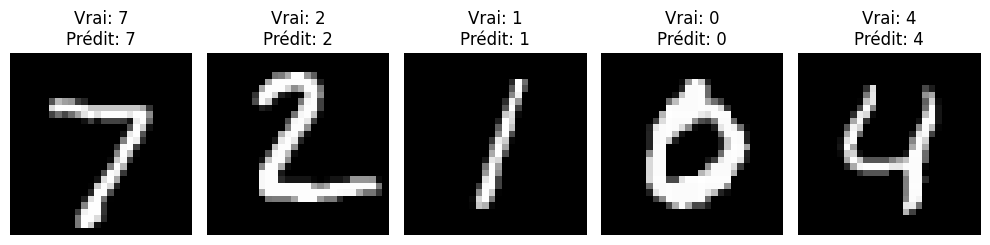

In [10]:
predictions = model.predict(x_test)

plt.figure(figsize=(10, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]}\nPrédit: {np.argmax(predictions[i])}")
    plt.axis('off')
plt.tight_layout()
plt.show()

## Réponses aux questions : Étape 9 (Prédictions et visualisation)

**1. Le modèle fait-il des erreurs ? Sur quelles images ?**
Sur les 5 premières images du test (7, 2, 1, 0, 4), le modèle prédit en général correctement. Sur l'ensemble des 10 000 images, il fait environ 2 à 3 % d'erreurs, surtout sur des chiffres mal écrits ou ambigus.

**2. Comment expliquer une prédiction erronée ?**
Chiffres ambigus ou mal tracés (4/9, 3/5, 7/1), modèle Dense qui ne voit pas la structure spatiale (il traite les pixels indépendamment), entraînement limité à 5 époques.

**3. Quelle technique permettrait d'améliorer la précision ?**
Un réseau convolutif (CNN) qui exploite la structure spatiale des images, éventuellement avec data augmentation et Dropout.

## Analyse personnelle : Exercice 1 (MNIST)

**Interprétation des résultats :** le réseau Dense (784 → 128 → 10) atteint environ 97–98 % de précision sur le test après 5 époques. La précision de validation suit celle d'entraînement avec un faible écart, donc pas de surapprentissage marqué à ce stade. La normalisation des pixels a facilité la convergence.

**Difficultés rencontrées :** compréhension de la forme des données.

**Propositions d'amélioration :** ajouter des couches cachées ou des neurones, utiliser du Dropout, ajuster le batch size et le taux d'apprentissage, et surtout passer à un CNN, plus adapté aux images.

#Exercice 2

In [11]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns

# Pour la reproductibilité
tf.random.set_seed(42)

# Chargement du dataset
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Dimensions du train set : (60000, 28, 28)
Dimensions du test set : (10000, 28, 28)
Type : uint8


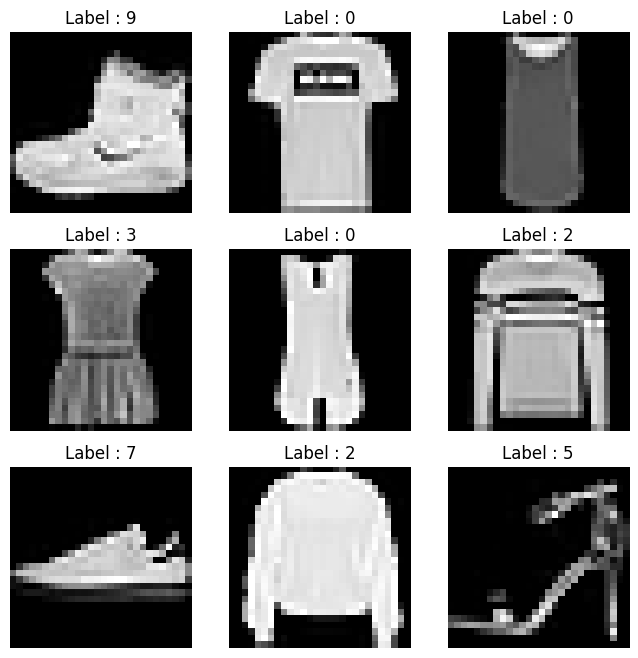

In [12]:
print("Dimensions du train set :", X_train.shape)
print("Dimensions du test set :", X_test.shape)
print("Type :", X_train.dtype)

plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label : {y_train[i]}")
    plt.axis('off')
plt.show()

## Réponse : Étape 1 (Exploration)

**Que remarquez-vous sur la nature des données et la taille des images ?**
Ce sont des images en niveaux de gris, de petite taille (28×28 pixels), de type `uint8` (0 à 255). Elles représentent des vêtements (pas des chiffres) et les labels sont des entiers de 0 à 9 correspondant à 10 classes (T-shirt, pantalon, pull, robe, manteau, sandale, chemise, basket, sac, bottine). Les images sont petites et centrées, ce qui rend l'entraînement rapide.

In [13]:
from tensorflow.keras.utils import to_categorical

# Normalisation des pixels entre 0 et 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Encodage one-hot des labels
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print(y_train[0], "->", y_train_cat[0])

9 -> [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


## Réponses aux questions : Étape 2 (Prétraitement)

**1. Pourquoi faut-il normaliser les images ?**
Pour ramener les pixels (0–255) entre 0 et 1 : entraînement plus stable, convergence plus rapide, gradients mieux conditionnés.

**2. Quelle est l'importance du one-hot encoding en classification multiclasse ?**
Il transforme un label entier (ex. 3) en vecteur de 10 valeurs (0,0,0,1,0,...). Sans cela, le modèle pourrait croire qu'il existe un ordre entre les classes (2 < 3 < 4). Il correspond aussi à la sortie softmax et à la loss `categorical_crossentropy`.

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7791 - loss: 0.6290 - val_accuracy: 0.8351 - val_loss: 0.4454
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8453 - loss: 0.4286 - val_accuracy: 0.8549 - val_loss: 0.4000
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8601 - loss: 0.3850 - val_accuracy: 0.8602 - val_loss: 0.3787
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8684 - loss: 0.3609 - val_accuracy: 0.8615 - val_loss: 0.3707
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8736 - loss: 0.3424 - val_accuracy: 0.8667 - val_loss: 0.3591
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8798 - loss: 0.3280 - val_accuracy: 0.8741 - val_loss: 0.3450
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8818 - loss: 0.3176 - val_accuracy: 0.8613 - val_loss: 0.3628
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8862 - loss: 0.3079 - val_accuracy: 0.

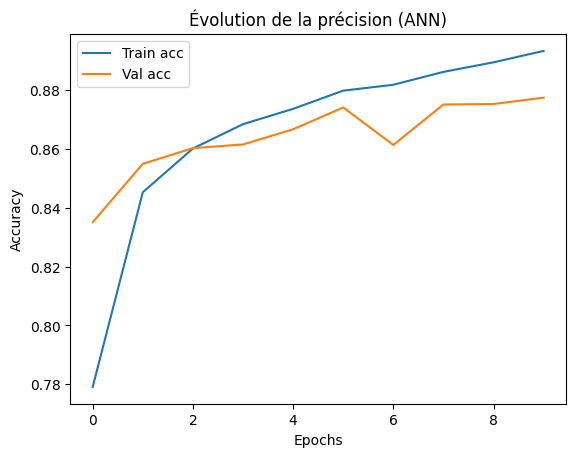

In [16]:
plt.plot(history.history['accuracy'], label='Train acc')
plt.plot(history.history['val_accuracy'], label='Val acc')
plt.legend()
plt.title('Évolution de la précision (ANN)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

In [17]:
test_loss, test_acc = model.evaluate(X_test, y_test_cat)
print("Précision sur le test set :", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8688 - loss: 0.3582
Précision sur le test set : 0.8687999844551086


## Réponses aux questions : Étape 3 (Modèle ANN)

**1. Pourquoi utilise-t-on ReLU ici ?**
Elle est simple et rapide à calculer, apporte la non-linéarité nécessaire et limite le problème de disparition du gradient (gradient = 1 pour x > 0).

**2. Quelle est la différence entre `accuracy` et `val_accuracy` ?**
- `accuracy` : précision sur les données d'entraînement (80 % du train ici).
- `val_accuracy` : précision sur les données de validation (20 % mis de côté), non utilisées pour ajuster les poids. Elle indique la capacité de généralisation.

**3. Que se passe-t-il avec 50 époques ?**
La précision d'entraînement continuerait d'augmenter tandis que la validation stagnerait (≈ 0.87–0.88 à 10 époques), ce qui indique un risque de surapprentissage. Le Dropout atténue un peu ce phénomène.

{'sigmoid': 0.8619999885559082, 'tanh': 0.8744166493415833, 'relu': 0.8769999742507935, 'LeakyReLU': 0.878166675567627}


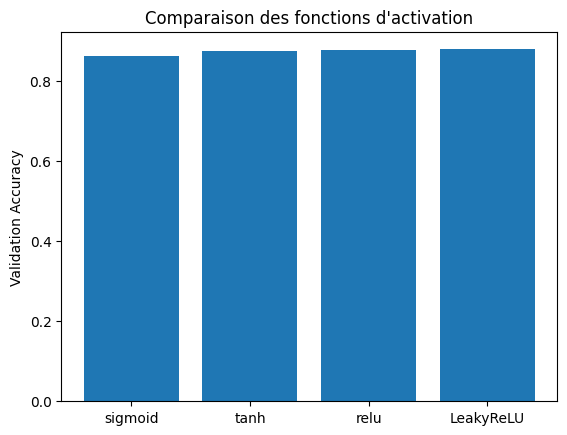

In [18]:
from tensorflow.keras.layers import LeakyReLU

activations = ['sigmoid', 'tanh', 'relu']
results = {}

for act in activations:
    model_act = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation=act),
        Dense(64, activation=act),
        Dense(10, activation='softmax')
    ])
    model_act.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = model_act.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
    results[act] = h.history['val_accuracy'][-1]

# Leaky ReLU
model_leaky = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128),
    LeakyReLU(0.1),
    Dense(64),
    LeakyReLU(0.1),
    Dense(10, activation='softmax')
])
model_leaky.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = model_leaky.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
results['LeakyReLU'] = h.history['val_accuracy'][-1]

print(results)

plt.bar(results.keys(), results.values())
plt.title("Comparaison des fonctions d'activation")
plt.ylabel("Validation Accuracy")
plt.show()

## Réponses aux questions : Étape 4 (Fonctions d'activation)

**1. Quelle fonction d'activation donne les meilleurs résultats ?**
LeakyReLU obtient la meilleure validation accuracy (0.8782), suivie de ReLU (0.8770), tanh (0.8744) et sigmoïde (0.8620). L'écart entre LeakyReLU, ReLU et tanh est très faible (un seul entraînement de 5 époques), seule la sigmoïde est nettement en retrait.

**2. Pourquoi sigmoïde et tanh sont moins utilisées dans les couches cachées ?**
Elles saturent pour des valeurs d'entrée grandes (positives ou négatives) : le gradient devient proche de 0 (problème de « vanishing gradient »), ce qui ralentit l'apprentissage des réseaux profonds. Elles sont aussi plus coûteuses à calculer que ReLU.

**3. À quoi sert LeakyReLU ?**
Elle laisse passer une petite pente pour x < 0 (ici 0.1x) au lieu de renvoyer 0. Cela évite le problème des « neurones morts » de ReLU (neurones qui ne s'activent plus jamais).

In [19]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

# Reshape pour ajouter la dimension "canal"
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

cnn = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])
cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN sur test set :", test_acc)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 30s 76ms/step - accuracy: 0.7655 - loss: 0.6479 - val_accuracy: 0.8500 - val_loss: 0.4205
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 39s 71ms/step - accuracy: 0.8507 - loss: 0.4114 - val_accuracy: 0.8704 - val_loss: 0.3544
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 27s 73ms/step - accuracy: 0.8715 - loss: 0.3545 - val_accuracy: 0.8799 - val_loss: 0.3207
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 36s 95ms/step - accuracy: 0.8844 - loss: 0.3175 - val_accuracy: 0.8863 - val_loss: 0.3014
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 28s 76ms/step - accuracy: 0.8919 - loss: 0.2958 - val_accuracy: 0.8875 - val_loss: 0.2969
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 39s 70ms/step - accuracy: 0.9012 - loss: 0.2738 - val_accuracy: 0.8977 - val_loss: 0.2795
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 26s 69ms/step - accuracy: 0.9046 - loss: 0.2588 - val_accuracy: 0.9001 - val_loss: 0.2706
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 25s 67ms/step - accuracy: 0.9115 - loss: 0.2446 - 

## Réponses aux questions : Étape 5 (CNN)

**1. Quelle est la différence entre un ANN et un CNN ?**
Un ANN (Dense) aplatit l'image et relie chaque pixel à chaque neurone, sans tenir compte de la position des pixels. Un CNN utilise des filtres convolutifs qui parcourent l'image et détectent des motifs locaux (bords, formes), avec des poids partagés.

**2. Pourquoi le CNN donne-t-il généralement de meilleurs résultats ?**
Il exploite la structure spatiale des images, apprend des caractéristiques hiérarchiques (bords → formes → objets), a moins de paramètres par couche grâce au partage de poids, et est plus robuste aux petits décalages.

**3. Quel est le rôle des couches de Pooling ?**
Elles réduisent la taille spatiale des cartes de caractéristiques (ici 2×2 : on garde le maximum de chaque zone). Cela diminue les calculs et le nombre de paramètres, et rend le modèle plus robuste aux petites translations.

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


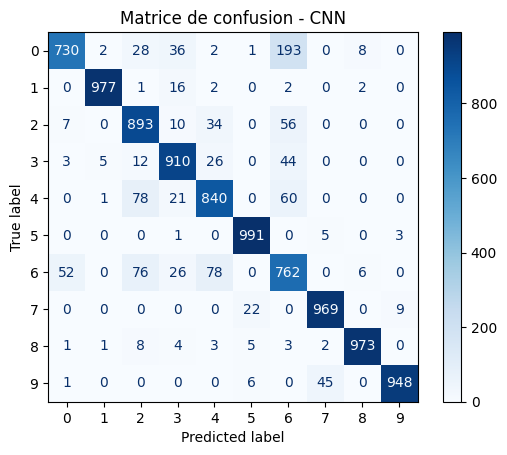

In [21]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = np.argmax(cnn.predict(X_test_cnn), axis=1)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matrice de confusion - CNN")
plt.show()

## Réponses aux questions : Étape 6 (Matrice de confusion)

**1. Quelles classes sont le plus souvent confondues ?**  **T-shirt (0), Pull (2), Manteau (4) et Chemise (6)**, qui se ressemblent beaucoup, la chemise étant la classe la plus difficile. Aussi parfois sandale / basket / bottine (5, 7, 9).

**2. Comment peut-on réduire ces erreurs ?**
Un CNN plus profond, plus d'époques avec early stopping, data augmentation, Dropout/BatchNormalization, ajustement des hyperparamètres, ou des modèles pré-entraînés.

In [22]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

datagen.fit(X_train_cnn)

cnn.fit(
    datagen.flow(X_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(X_test_cnn, y_test_cat)
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 42s 88ms/step - accuracy: 0.8616 - loss: 0.3815 - val_accuracy: 0.9006 - val_loss: 0.2733
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 39s 83ms/step - accuracy: 0.8796 - loss: 0.3287 - val_accuracy: 0.8990 - val_loss: 0.2773
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 40s 85ms/step - accuracy: 0.8858 - loss: 0.3123 - val_accuracy: 0.9046 - val_loss: 0.2610
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 39s 84ms/step - accuracy: 0.8905 - loss: 0.2975 - val_accuracy: 0.8946 - val_loss: 0.2821
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 39s 84ms/step - accuracy: 0.8918 - loss: 0.2911 - val_accuracy: 0.9003 - val_loss: 0.2698
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 39s 84ms/step - accuracy: 0.8961 - loss: 0.2827 - val_accuracy: 0.9063 - val_loss: 0.2547
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 40s 85ms/step - accuracy: 0.8991 - loss: 0.2763 - val_accuracy: 0.9093 - val_loss: 0.2584
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 39s 84ms/step - accuracy: 0.9007 - loss: 0.2709 - 

## Réponses aux questions : Étape 7 (Data Augmentation)

**1. Quel est l'intérêt de la Data Augmentation ?**
Elle crée des variantes des images d'entraînement (rotation, zoom, symétrie). Le modèle voit plus de variété, généralise mieux et surapprend moins, sans collecter de nouvelles données.Dans notre essai, la data augmentation n'a pas apporté de gain net en 10 époques supplémentaires (val_accuracy 0.9042 avant, 0.9036 après). Le modèle ne surapprenait pas encore, et l'entraînement a repris sur le même CNN déjà entraîné, donc la comparaison n'est pas parfaitement propre.

**2. Quels types de transformations semblent les plus efficaces pour ce dataset ?**
Le retournement horizontal (un vêtement reste le même vêtement) et les petites rotations/zooms (±10 %, 0.1) sont adaptés. Les rotations fortes ou le retournement vertical sont à éviter : une chaussure ou un pull à l'envers n'est pas réaliste.

## Analyse personnelle : Exercice 2 (Fashion-MNIST)

**Interprétation des résultats :** l'ANN atteint 86,9 % de précision sur le test, contre 89,9 % pour le CNN, qui exploite la structure spatiale des images (+3 points). Pour les activations, LeakyReLU (0.878), ReLU (0.877) et tanh (0.874) sont proches, la sigmoïde est la plus faible (0.862). La data augmentation n'a pas amélioré les résultats de façon visible sur 10 époques.

**Difficultés rencontrées :** temps d'entraînement du CNN, reshape pour ajouter la dimension canal, compréhension du one-hot.

**Propositions d'amélioration :** CNN plus profond avec BatchNormalization, early stopping, réglage du taux d'apprentissage et du batch size, plus d'époques, ou transfer learning.